> **Production run.** Same notebook with the numbers of replicas, toy experiments and chain lengths of the report. Run with `run_full.sh`; expect several hours.

# 02 · Frequentist analysis (2/4): validation of the estimator and of the intervals

**What this notebook does.** Checks that the fit of notebook 01 gives an *unbiased* estimator with intervals of *nominal
coverage* and a test of $A=0$ with the *nominal size*: bootstrap of the data, toy experiments from the fitted model
(bias, pulls, coverage, size and power), Neyman confidence belt, dependence on the momentum of the $B$, and the goodness
of fit against the binning.

| § | Content | Report section |
|---|---|---|
| 5 | Coverage of the Wilks interval: bootstrap | Frequentist analysis |
| 6 | Toy experiments, Neyman belt, momentum, goodness of fit and binning | Validation of the estimator (add.: Neyman, binning) |

The section numbers are those of the whole frequentist study. The first part (*Common setup*) repeats the data and the
nominal fit of notebook 01 so that this notebook runs on its own.

**Scale.** A guided tour of the method, not the production run: replicas, toy experiments and chains are fewer than in
the report, so numbers can differ slightly from it; next to every result the notebook prints the value of the report
(**report:**). The notebook is self-contained and saves its figures in `figures/` and its numbers in `results/`.
Parts beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Common setup (data and nominal fit, as in notebook 01)

## 0 · Setup

In [1]:
import os, time, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.stats import norm, chi2
from iminuit import Minuit, cost

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()

# Data: put the three .root files of CERN Open Data record 4900 in ./data (or edit the path)
DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
np.random.seed(1)

# figures and numerical results are saved next to the notebook
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    """Save the current figure in figures/ and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

M_K = 493.677            # charged-kaon mass [MeV]
LO, HI = 5100.0, 5600.0  # nominal fit window of the mass [MeV]

## 1 · Data and preselection

The record contains $B^\pm\to h^\pm h^+h^-$ candidates (2011 data, 7 TeV), one file per magnet polarity. Every
candidate has the momentum, the particle-identification (PID) likelihoods and the charge of the three tracks
$H_1,H_2,H_3$. We read only the branches we need.

In [2]:
tracks = (1, 2, 3)                     # the three final-state hadrons H1, H2, H3
# branches to read for each track: momentum, PID likelihoods, muon flag, charge
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]

frames = []
for pol in ("Down", "Up"):             # one file per magnet polarity
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        d = f["DecayTree"].arrays(branches, library="pd")      # read the tree into a pandas DataFrame
    d["magnet"] = pol.lower()          # remember the polarity of each candidate
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
print("candidates in the record:", len(df))

candidates in the record: 8556118


**Preselection.** We want $B^\pm\to K^\pm K^+K^-$: all three tracks must look like kaons and not like pions or muons,

$$\texttt{ProbPi}<0.5\ \wedge\ \texttt{ProbK}>0.5\ \wedge\ \lnot\texttt{isMuon}\quad\text{for each of the three tracks.}$$

The cut flow below gives the effect of each requirement alone and cumulatively (additional result of the report).

In [3]:
# boolean masks, True when the requirement is satisfied by ALL three tracks
not_muon = np.ones(len(df), bool)
pi_ok = np.ones(len(df), bool)
k_ok = np.ones(len(df), bool)
for i in tracks:
    not_muon &= ~df[f"H{i}_isMuon"].to_numpy().astype(bool)    # not identified as a muon
    pi_ok    &= df[f"H{i}_ProbPi"].to_numpy() < 0.5            # not pion-like
    k_ok     &= df[f"H{i}_ProbK"].to_numpy() > 0.5             # kaon-like

# cut flow: how many candidates pass each requirement alone, and applying them one after the other
print(f"{'requirement':28s} {'alone':>10s} {'cumulative':>11s}")
cum = np.ones(len(df), bool)
cutflow_rows = []
for name, mask in (("not muon (3 tracks)", not_muon), ("ProbPi < 0.5 (3 tracks)", pi_ok), ("ProbK > 0.5 (3 tracks)", k_ok)):
    cum &= mask
    print(f"{name:28s} {mask.sum():10d} {cum.sum():11d}")
    cutflow_rows.append((name, int(mask.sum()), int(cum.sum())))
print("report: 6311517 / 975724 / 28812 alone, 23895 cumulative")
pd.DataFrame(cutflow_rows, columns=["requirement", "alone", "cumulative"]).to_csv("results/01_cutflow.csv", index=False)

requirement                       alone  cumulative
not muon (3 tracks)             6311517     6311517
ProbPi < 0.5 (3 tracks)          975724      481101
ProbK > 0.5 (3 tracks)            28812       23895
report: 6311517 / 975724 / 28812 alone, 23895 cumulative


**Invariant mass.** We give the kaon mass to the three tracks, sum the four-momenta and take $m^2=E^2-|\vec p|^2$.
The two opposite-sign pairs $m(H_1H_2)$ and $m(H_1H_3)$ are kept for the Dalitz plane ($H_1$ is always the kaon with
charge opposite to the $B$).

We keep a slightly looser sample (`ProbK > 0.3`, `ProbPi < 0.7`) and store the *weakest* PID value of each
candidate: later the systematic study and the PID scan simply re-apply tighter cuts on these columns.

In [4]:
loose = np.ones(len(df), bool)
for i in tracks:
    loose &= (df[f"H{i}_ProbK"] > 0.3) & (df[f"H{i}_ProbPi"] < 0.7) & ~df[f"H{i}_isMuon"].astype(bool)
d = df[loose].reset_index(drop=True)
del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks, kaon mass hypothesis."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"]  = invariant_mass(d, (1, 2, 3))
d["m12"], d["m13"] = invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"]  = d.H1_Charge + d.H2_Charge + d.H3_Charge              # charge of the B
d["pT"] = np.sqrt(sum(d[f"H{i}_PX"] for i in tracks)**2 + sum(d[f"H{i}_PY"] for i in tracks)**2)
d["p"]  = np.sqrt(d.pT**2 + sum(d[f"H{i}_PZ"] for i in tracks)**2)
d["min_probk"]  = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)
d["max_probpi"] = d[[f"H{i}_ProbPi" for i in tracks]].max(axis=1)
d = d[np.abs(d.q) == 1]
assert (d.H1_Charge == -d.q).all()          # H1 has the opposite charge of the B

nominal = d[(d.min_probk > 0.5) & (d.max_probpi < 0.5)]
sample = nominal[(nominal.m > LO) & (nominal.m < HI)].reset_index(drop=True)
print(f"preselected: {len(nominal)} (report 23895);  in the window [{LO:.0f},{HI:.0f}]: {len(sample)} (report 19731)")
m_pos = sample.m[sample.q > 0].to_numpy()       # B+
m_neg = sample.m[sample.q < 0].to_numpy()       # B-
n_pos, n_neg = len(m_pos), len(m_neg)

preselected: 23895 (report 23895);  in the window [5100,5600]: 19731 (report 19731)


## 2 · Mass model and likelihood

For each charge the mass spectrum is a mixture of signal and background on the window $[5100,5600]$ MeV,

$$f^\pm(m)=N_s^\pm\,S(m;\mu,\sigma)+N_b^\pm\,B^\pm(m),\qquad
N_s^\pm=\tfrac{N_s}{2}(1\mp A),$$

* **signal** $S$: Gaussian, truncated and normalised to the window; $\mu,\sigma$ are *shared* by $B^+$ and $B^-$;
* **background** $B^\pm$: sum of two exponentials, $f\,E(\lambda_1)+(1-f)\,E(\lambda_2)$, with a shape and a yield of
  its own for each charge (the steep exponential describes the rise of the background towards the lower edge);
* **$A$** is a parameter of the fit: it is the *parameter of interest* (POI); the other 11 are *nuisance parameters*.

The likelihood is *extended* (the yields are parameters, the number of candidates is Poisson):

$$-\ln\mathcal L=(N_s+N_b)-\sum_{\pm}\sum_{i\in\pm}\ln\!\big[N_s^\pm S(m_i)+N_b^\pm B^\pm(m_i)\big]+\text{const.}$$

We write the pdfs ourselves (a few lines each) and let `iminuit` build the extended likelihood with
`cost.ExtendedUnbinnedNLL`: the model is a function `model(m, *parameters)` that returns the expected total number
of events and the density of events at $m$.

In [5]:
def gauss_pdf(m, mu, sigma, lo=LO, hi=HI):
    """Gaussian normalised on [lo, hi]."""
    return norm.pdf(m, mu, sigma) / (norm.cdf(hi, mu, sigma) - norm.cdf(lo, mu, sigma))

def exp_pdf(m, lam, lo=LO, hi=HI):
    """Decreasing exponential exp(-lam (m - lo)) normalised on [lo, hi]."""
    return lam * np.exp(-lam * (m - lo)) / (1 - np.exp(-lam * (hi - lo)))

def bkg_pdf(m, lam1, lam2, f, lo=LO, hi=HI):
    """Background: two exponentials, weight f on the steep one (lam1 > lam2)."""
    return f * exp_pdf(m, lam1, lo, hi) + (1 - f) * exp_pdf(m, lam2, lo, hi)

# one model per charge; the parameters with the same name (N_s, A, mu, sigma) are shared in the joint fit
def model_pos(m, N_s, A, mu, sigma, N_b_pos, lam1_pos, lam2_pos, f_pos):
    n_sig = N_s * (1 - A) / 2                       # B+ : (1 - A) / 2
    return n_sig + N_b_pos, n_sig * gauss_pdf(m, mu, sigma) + N_b_pos * bkg_pdf(m, lam1_pos, lam2_pos, f_pos)

def model_neg(m, N_s, A, mu, sigma, N_b_neg, lam1_neg, lam2_neg, f_neg):
    n_sig = N_s * (1 + A) / 2                       # B- : (1 + A) / 2
    return n_sig + N_b_neg, n_sig * gauss_pdf(m, mu, sigma) + N_b_neg * bkg_pdf(m, lam1_neg, lam2_neg, f_neg)

### 3.2 Simultaneous fit: the nominal result

The two charges are fitted *together*: the total cost is the sum of the two extended likelihoods and $A$ is a
parameter of it, so the profile likelihood of $A$ is available directly. `Migrad` minimises, `Hesse` gives the
symmetric uncertainties from the curvature (inverse of the Fisher information) and `Minos` the asymmetric
intervals from the profile likelihood.

In [6]:
def fit_joint(m_p, m_n, start, a_fixed=None):
    """Simultaneous fit of B+ and B-: the cost is the sum of the two extended likelihoods.
    With a_fixed the asymmetry is held at that value (profile likelihood at that point)."""
    nll = cost.ExtendedUnbinnedNLL(m_p, model_pos) + cost.ExtendedUnbinnedNLL(m_n, model_neg)
    f = Minuit(nll, **start)
    f.limits["A"] = (-1, 1); f.limits["mu"] = (5260, 5310); f.limits["sigma"] = (3, 40)
    f.limits["N_s"] = (0, 2 * (len(m_p) + len(m_n)))
    for s in ("pos", "neg"):
        f.limits[f"N_b_{s}"] = (0, 2 * (len(m_p) + len(m_n)))
        f.limits[f"lam1_{s}"] = (1e-5, 0.1); f.limits[f"lam2_{s}"] = (1e-5, 0.1); f.limits[f"f_{s}"] = (0, 1)
    if a_fixed is not None:
        f.values["A"] = a_fixed
        f.fixed["A"] = True
    f.migrad()
    return f

start = dict(N_s=0.78 * len(sample), A=-0.04, mu=5284.0, sigma=18.0,
             N_b_pos=0.22 * n_pos, lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15,
             N_b_neg=0.22 * n_neg, lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)
fit = fit_joint(m_pos, m_neg, start)
best_vals_start = {k: fit.values[k] for k in start}      # best-fit values, used as starting point of later fits
fit.migrad(); fit.hesse()
fit.minos("A")                                      # 68 % interval (default cl = 1 sigma)
ci68 = (fit.values["A"] + fit.merrors["A"].lower, fit.values["A"] + fit.merrors["A"].upper)
fit_95 = copy.deepcopy(fit); fit_95.minos("A", cl=0.95)
ci95 = (fit_95.values["A"] + fit_95.merrors["A"].lower, fit_95.values["A"] + fit_95.merrors["A"].upper)

assert fit.valid and fit.values["lam1_pos"] > fit.values["lam2_pos"] and fit.values["lam1_neg"] > fit.values["lam2_neg"]
for k in ("N_s", "A", "mu", "sigma"):
    print(f"{k:8s} = {fit.values[k]:12.4f} +- {fit.errors[k]:.4f}")
print(f"N_b = {fit.values['N_b_pos'] + fit.values['N_b_neg']:.0f}")
print(f"\nA_raw = {fit.values['A']:+.4f} +- {fit.errors['A']:.4f} (Hesse)")
print(f"  68% Minos [{ci68[0]:+.4f}, {ci68[1]:+.4f}]    report: [-0.0526, -0.0356]")
print(f"  95% Minos [{ci95[0]:+.4f}, {ci95[1]:+.4f}]    report: [-0.0607, -0.0275]")
print("report: A = -0.0441 +- 0.0085, N_s = 15328 +- 133")

N_s      =   15328.0758 +- 132.9289
A        =      -0.0441 +- 0.0085
mu       =    5284.3784 +- 0.1592
sigma    =      18.0018 +- 0.1407
N_b = 4403

A_raw = -0.0441 +- 0.0085 (Hesse)
  68% Minos [-0.0526, -0.0356]    report: [-0.0526, -0.0356]
  95% Minos [-0.0607, -0.0275]    report: [-0.0607, -0.0275]
report: A = -0.0441 +- 0.0085, N_s = 15328 +- 133


**Reading the result.** $A_{\rm raw}\approx-0.044$ with a Hesse uncertainty of $0.0085$: the asymmetry is about five standard deviations from zero. The Minos intervals are the ranges where the profile likelihood is within $1$ and $1.96^2$ units of its minimum; they are slightly asymmetric and the 95 % one does not contain zero.

In [7]:
# table of the 12 parameters of the nominal fit, with their Hesse uncertainties, saved for later use
par_table = pd.DataFrame({"value": [fit.values[k] for k in fit.parameters], "hesse": [fit.errors[k] for k in fit.parameters]},
                         index=list(fit.parameters))
par_table.to_csv("results/01_fit_parameters.csv")
print(par_table.round(5).to_string())

                value      hesse
N_s       15328.07579  132.92894
A            -0.04410    0.00850
mu         5284.37840    0.15915
sigma        18.00178    0.14072
N_b_pos    2290.01474   57.57399
lam1_pos      0.03540    0.00763
lam2_pos      0.00281    0.00028
f_pos         0.11233    0.02740
N_b_neg    2112.93866   55.63303
lam1_neg      0.02760    0.00468
lam2_neg      0.00163    0.00040
f_neg         0.21025    0.03897


### 3.3 Goodness of fit and picture

The $\chi^2=\sum_i(n_i-\nu_i)^2/\nu_i$ in bins of 10 MeV (both charges, $\nu_i$ from the fitted model) with
$\mathrm{ndof}=2\times50-12$. The pulls $(n_i-\nu_i)/\sqrt{\nu_i}$ show *where* the model fails. (The model is not
perfect: the signal tails are heavier than a Gaussian; $A_{\rm raw}$ does not depend on it, see §7.)

chi2/ndof = 159.5/88,  p = 4.8e-06     (report: 160/88, p = 4.8e-6)


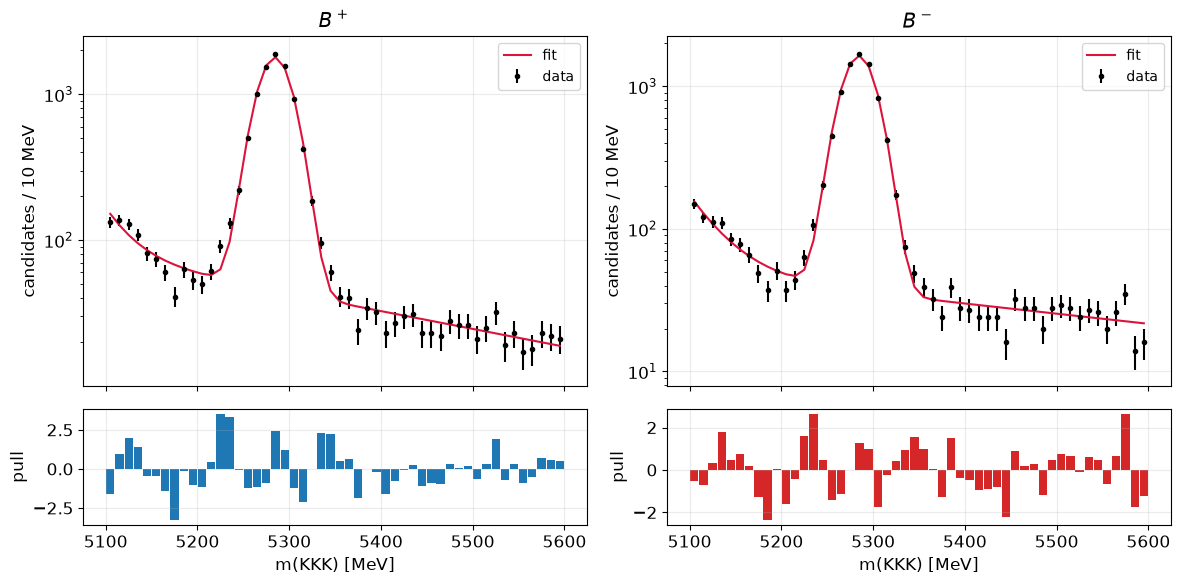

In [8]:
def expected_counts(model, args, edges, n_sub=5):
    """Expected counts per bin: mean of the density at n_sub points in each bin, times the width."""
    width = edges[1] - edges[0]
    offs = (np.arange(n_sub) + 0.5) / n_sub                       # sub-points inside a bin
    pts = edges[:-1, None] + offs[None, :] * width                # shape (n_bins, n_sub)
    return model(pts, *args)[1].mean(axis=1) * width

edges = np.arange(LO, HI + 1e-9, 10.0)                            # bins of 10 MeV
centers = 0.5 * (edges[1:] + edges[:-1])
v = fit.values
# expected number of events in each bin for B+ and B-, from the fitted model
nu_pos = expected_counts(model_pos, [v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_pos", "lam1_pos", "lam2_pos", "f_pos")], edges)
nu_neg = expected_counts(model_neg, [v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_neg", "lam1_neg", "lam2_neg", "f_neg")], edges)
obs_pos, obs_neg = np.histogram(m_pos, edges)[0], np.histogram(m_neg, edges)[0]    # observed counts
chi2_val = np.sum((obs_pos - nu_pos)**2 / nu_pos) + np.sum((obs_neg - nu_neg)**2 / nu_neg)   # Pearson chi2
ndof = 2 * len(centers) - 12                                      # bins of both charges minus parameters
print(f"chi2/ndof = {chi2_val:.1f}/{ndof},  p = {chi2.sf(chi2_val, ndof):.1e}     (report: 160/88, p = 4.8e-6)")

# data with the fit (top) and pulls (bottom): the pulls show WHERE the model fails
pd.DataFrame({"m_center": centers, "obs_pos": obs_pos, "model_pos": nu_pos, "obs_neg": obs_neg, "model_neg": nu_neg}).to_csv(
    "results/01_mass_fit_bins.csv", index=False)    # data and model per bin
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for col, (obs, nu, lab, c) in enumerate(((obs_pos, nu_pos, "$B^+$", C["pos"]), (obs_neg, nu_neg, "$B^-$", C["neg"]))):
    ax[0, col].errorbar(centers, obs, np.sqrt(obs), fmt="o", ms=3, color="k", label="data")
    ax[0, col].plot(centers, nu, color=C["model"], label="fit")
    ax[0, col].set(yscale="log", ylabel="candidates / 10 MeV", title=lab); ax[0, col].legend()
    ax[1, col].bar(centers, (obs - nu) / np.sqrt(nu), width=9, color=c)
    ax[1, col].set(xlabel="m(KKK) [MeV]", ylabel="pull")
plt.tight_layout(); save_fig("02_joint_fit_pulls")

**Reading the result.** $\chi^2/{\rm ndof}$ is well above 1 and the $p$-value tiny: the model is **not** a perfect description of the spectrum (the pulls show structure on the flanks of the peak, where the signal tails are heavier than a Gaussian). What matters for the measurement is whether this affects $A$: the signal-model variants of notebook 03 say that it does not.

In [9]:
# purity of the signal window |m - mu| < 2 sigma: signal / (signal + background) in the window, from the fit
mu_f, sg_f = fit.values["mu"], fit.values["sigma"]
x_w = np.linspace(mu_f - 2 * sg_f, mu_f + 2 * sg_f, 2001)
sig_in = fit.values["N_s"] * np.trapezoid(gauss_pdf(x_w, mu_f, sg_f), x_w)
bkg_in = sum(fit.values[f"N_b_{s}"] * np.trapezoid(bkg_pdf(x_w, fit.values[f"lam1_{s}"], fit.values[f"lam2_{s}"], fit.values[f"f_{s}"]), x_w)
             for s in ("pos", "neg"))
print(f"signal in the window: {sig_in:.0f}, background: {bkg_in:.0f}, purity {sig_in / (sig_in + bkg_in):.3f}   (report: about 96 %)")

signal in the window: 14631, background: 593, purity 0.961   (report: about 96 %)


In [10]:
best_vals = dict(best_vals_start)      # best-fit values of the nominal fit, starting point of the later fits

## 5 · Coverage of the Wilks interval: bootstrap of the data

Wilks' theorem is *asymptotic*. To check that the interval $q\le1$ really contains the true value 68 % of the time
we resample the data: each replica is a sample of $N$ candidates drawn **with replacement** from the observed ones
(`np.random.choice`, as in the course), refitted with the nominal model. We take $A_{\rm true}$ equal to the fitted
value; the 68 % interval of a replica contains it if and only if $t=q(A_{\rm true})\le 1$, where
$q(A_{\rm true})$ is evaluated *on the replica*.

*Report:* 1000 replicas, coverage $68.4\pm1.5\,\%$. Here: 60.

             hesse  bootstrap   ratio
N_s       132.9289    74.1356  0.5577
A           0.0085     0.0084  0.9901
mu          0.1592     0.1643  1.0321
sigma       0.1407     0.1511  1.0735
N_b_pos    57.5740    54.3495  0.9440
lam1_pos    0.0076     0.0055  0.7166
lam2_pos    0.0003     0.0003  0.9981
f_pos       0.0274     0.0289  1.0545
N_b_neg    55.6330    53.6151  0.9637
lam1_neg    0.0047     0.0042  0.8891
lam2_neg    0.0004     0.0004  0.9405
f_neg       0.0390     0.0369  0.9474
report: Hesse, bootstrap (and posterior) agree for A, A_b, mu, sigma; the bootstrap differs for the two yields (fixed N)
500 valid replicas (1185 s)
coverage of the 68.3% interval: 0.694 +- 0.021     (report: 0.684 +- 0.015)
pulls: mean +0.02, width 0.99


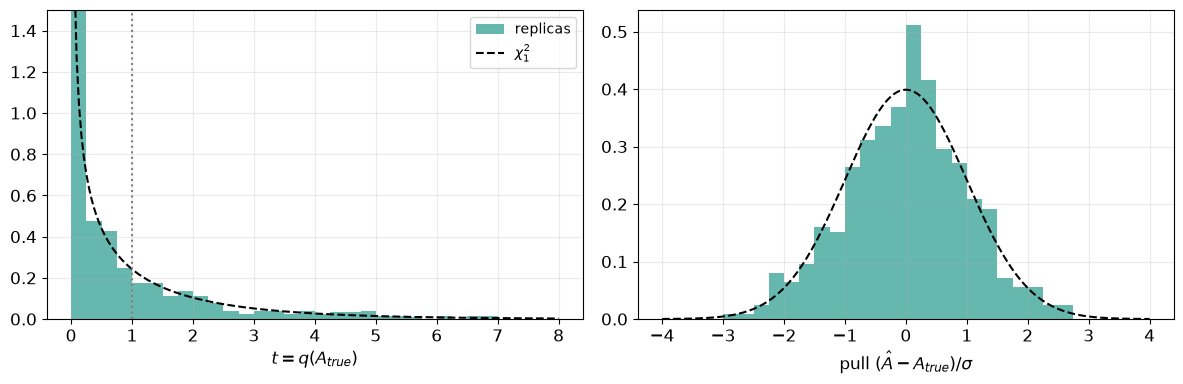

In [11]:
A_hat = fit.values["A"]                                      # best-fit asymmetry, taken as the "true" value
best_vals = {k: fit.values[k] for k in start}                # starting point of every replica: the best fit
best_vals["A"] = A_hat

def one_replica(m_p, m_n, a_true):
    """Fits one (pseudo-)dataset three times: free, with A fixed at a_true and with A fixed at 0.
    Returns A_hat, sigma(A_hat), t = q(a_true), q(0) and whether the three fits are valid."""
    f1 = fit_joint(m_p, m_n, best_vals); f1.hesse()           # free fit: estimate and Hesse error
    f2 = fit_joint(m_p, m_n, best_vals, a_true)               # A fixed at the true value
    f3 = fit_joint(m_p, m_n, best_vals, 0.0)                  # A fixed at zero (null hypothesis)
    ok = f1.valid and f2.valid and f3.valid
    # profile likelihood ratios: difference of -2 ln L between the constrained and the free fit
    return f1.values["A"], f1.errors["A"], f2.fval - f1.fval, f3.fval - f1.fval, ok, {k: f1.values[k] for k in f1.parameters}

N_BOOT = 500
t0 = time.time()
rows = []
q_all = sample.q.to_numpy()
m_all = sample.m.to_numpy()
for b in range(N_BOOT):
    # bootstrap replica: N candidates drawn WITH replacement from the observed ones
    idx = np.random.choice(len(sample), len(sample), replace=True)
    rows.append(one_replica(m_all[idx][q_all[idx] > 0], m_all[idx][q_all[idx] < 0], A_hat))
boot = pd.DataFrame(rows, columns=["A", "sigma", "t", "q0", "valid", "params"])
boot = boot[boot.valid]                                       # discard fits that did not converge
# uncertainty of each of the 12 parameters: Hesse matrix of the fit against the spread over the bootstrap replicas
par_boot = pd.DataFrame(list(boot.params))
unc_table = pd.DataFrame({"hesse": [fit.errors[k] for k in par_boot.columns], "bootstrap": par_boot.std().values}, index=par_boot.columns)
unc_table["ratio"] = unc_table.bootstrap / unc_table.hesse
unc_table.to_csv("results/02_parameter_uncertainties.csv")
print(unc_table.round(4).to_string())
print("report: Hesse, bootstrap (and posterior) agree for A, A_b, mu, sigma; the bootstrap differs for the two yields (fixed N)")
# the 68 % interval of a replica contains A_true if and only if t = q(A_true) <= 1
cov68 = np.mean(boot.t <= 1.0); err68 = np.sqrt(cov68 * (1 - cov68) / len(boot))
pulls = (boot.A - A_hat) / boot.sigma                         # should be ~ N(0, 1)
print(f"{len(boot)} valid replicas ({time.time() - t0:.0f} s)")
print(f"coverage of the 68.3% interval: {cov68:.3f} +- {err68:.3f}     (report: 0.684 +- 0.015)")
print(f"pulls: mean {pulls.mean():+.2f}, width {pulls.std():.2f}")

# left: distribution of t against the chi2 with one degree of freedom (Wilks); right: pulls against a Gaussian
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(boot.t, bins=np.linspace(0, 8, 33), density=True, color=C["freq"], alpha=0.6, label="replicas")
x = np.linspace(0.05, 8, 200); ax[0].plot(x, chi2.pdf(x, 1), "k--", label="$\\chi^2_1$")
ax[0].axvline(1, color="gray", ls=":"); ax[0].set(xlabel="$t=q(A_{true})$", ylim=(0, 1.5)); ax[0].legend()
ax[1].hist(pulls, bins=np.linspace(-4, 4, 33), density=True, color=C["freq"], alpha=0.6)
x = np.linspace(-4, 4, 200); ax[1].plot(x, norm.pdf(x), "k--"); ax[1].set(xlabel="pull $(\\hat A-A_{true})/\\sigma$")
plt.tight_layout(); save_fig("02_bootstrap_coverage")

**Reading the result.** The fraction of replicas whose 68 % interval contains the true value is compatible with 68.3 % within its statistical error (left: $t$ follows the $\chi^2_1$ distribution of Wilks' theorem; right: the pulls are $\approx N(0,1)$). With 1000 replicas the report finds $68.4\pm1.5$ %.

## 6 · Validation with toy experiments

The bootstrap resamples the *data*; here we generate **pseudo-experiments from the fitted model**, where we *know*
the true value, and check the estimator and the test:

* **bias** of $\hat A$ and **pulls** $(\hat A-A_{\rm true})/\sigma(\hat A)$ (mean 0, width 1 if unbiased and at the
  Cramér–Rao bound);
* **coverage** of $q(A_{\rm true})\le1$ and $\le3.84$;
* **size** of the test of $A=0$ (fraction of rejections at $A_{\rm true}=0$, nominal 5 %) and **power** (fraction
  of rejections at $A_{\rm true}\neq0$);
* the **Neyman construction**: the central 68 %/95 % ranges of $\hat A$ as a function of $A_{\rm true}$ (the
  *confidence belt*), read at the observed $\hat A$.

The toy is built by the **transformation method** (inverse cdf of uniform random numbers) for the Gaussian
and for the exponentials, with Poisson yields.

In [12]:
# --- random numbers by the transformation method: x = F^-1(u) with u uniform in [0, 1]
def sample_gauss(mu, sigma, n):
    """Gaussian truncated to the window: u is uniform between F(LO) and F(HI), then x = F^-1(u)."""
    u = np.random.uniform(norm.cdf(LO, mu, sigma), norm.cdf(HI, mu, sigma), n)
    return mu + sigma * norm.ppf(u)

def sample_exp(lam, n):
    """Exponential exp(-lam (m - LO)) truncated to the window, by inversion of its cdf."""
    u = np.random.uniform(size=n)
    return LO - np.log(1 - u * (1 - np.exp(-lam * (HI - LO)))) / lam

def sample_bkg(lam1, lam2, f, n):
    """Double exponential: each event comes from the steep component with probability f."""
    steep = np.random.uniform(size=n) < f
    return np.where(steep, sample_exp(lam1, n), sample_exp(lam2, n))

def make_toy(v, A_true):
    """One pseudo-experiment (m_pos, m_neg) from the parameters v of the nominal fit and asymmetry A_true."""
    out = []
    for side, sign in (("pos", -1), ("neg", +1)):
        n_s = np.random.poisson(v["N_s"] * (1 + sign * A_true) / 2)       # Poisson number of signal events
        n_b = np.random.poisson(v[f"N_b_{side}"])                         # and of background events
        m = np.concatenate([sample_gauss(v["mu"], v["sigma"], n_s),
                            sample_bkg(v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"], n_b)])
        out.append(m)
    return out

# a few values of the injected asymmetry: the fitted one (most toys) and others around it and zero
A_GRID = [-0.10, -0.07, A_hat, -0.02, 0.0, 0.05]
N_TOY = {a: (1000 if a == A_hat else 300) for a in A_GRID}       # report: 1000 at the fitted value, 300 at the others
t0 = time.time()
toy_rows = []
for a_true in A_GRID:
    for k in range(N_TOY[a_true]):
        mp, mn = make_toy(best_vals, a_true)                  # generate ...
        A, sig, t, q0, ok, _ = one_replica(mp, mn, a_true)    # ... and fit
        toy_rows.append((a_true, A, sig, t, q0, ok))
toys = pd.DataFrame(toy_rows, columns=["A_true", "A", "sigma", "t", "q0", "valid"])
print(f"{len(toys)} toys, {(~toys.valid).sum()} not valid ({time.time() - t0:.0f} s)")
toys = toys[toys.valid]

2500 toys, 0 not valid (4885 s)


In [13]:
# one line per injected value of A: bias, spread against Hesse error, pulls, coverage, size/power of the test of A = 0
print(f"{'A_true':>8s} {'n':>4s} {'bias':>9s} {'spread/<Hesse>':>15s} {'pull mean':>10s} {'pull sd':>8s} "
      f"{'cov68':>6s} {'cov95':>6s} {'P(q0>3.84)':>11s} {'P(q0>9)':>8s}")
for a_true, g in toys.groupby("A_true"):
    pull = (g.A - a_true) / g.sigma
    print(f"{a_true:+8.4f} {len(g):4d} {g.A.mean() - a_true:+9.5f} {g.A.std() / g.sigma.mean():15.2f} {pull.mean():+10.2f} "
          f"{pull.std():8.2f} {np.mean(g.t <= 1):6.2f} {np.mean(g.t <= 3.84):6.2f} {np.mean(g.q0 > 3.84):11.2f} {np.mean(g.q0 > 9):8.2f}")
print("report (1000 toys at the fitted value): bias <= 0.0008, pulls width 0.94-1.05, cov68 0.696 +- 0.015, "
      "cov95 0.954 +- 0.007, size 0.051 +- 0.013, power(-0.02) 0.68")

  A_true    n      bias  spread/<Hesse>  pull mean  pull sd  cov68  cov95  P(q0>3.84)  P(q0>9)
 -0.1000  300  -0.00081            0.99      -0.10     0.99   0.70   0.93        1.00     1.00
 -0.0700  300  +0.00034            1.00      +0.04     1.00   0.67   0.94        1.00     1.00
 -0.0441 1000  -0.00045            1.00      -0.05     1.00   0.66   0.95        1.00     0.99
 -0.0200  300  +0.00025            0.95      +0.03     0.95   0.69   0.97        0.64     0.25
 +0.0000  300  +0.00007            1.05      +0.01     1.05   0.67   0.93        0.07     0.00
 +0.0500  300  +0.00012            0.98      +0.01     0.98   0.66   0.96        1.00     1.00
report (1000 toys at the fitted value): bias <= 0.0008, pulls width 0.94-1.05, cov68 0.696 +- 0.015, cov95 0.954 +- 0.007, size 0.051 +- 0.013, power(-0.02) 0.68


**Reading the table.** One row per injected asymmetry: the bias is compatible with zero, the spread equals the mean Hesse uncertainty and the pulls have width $\approx1$ (unbiased estimator at the minimum variance bound); the coverage of $q\le1$ and $q\le3.84$ is close to $68$ % and $95$ %. For $A_{\rm true}=0$ the last two columns are the **size** of the test of $A=0$ (about 5 % for $q_0>3.84$); for the other rows they are its **power**.

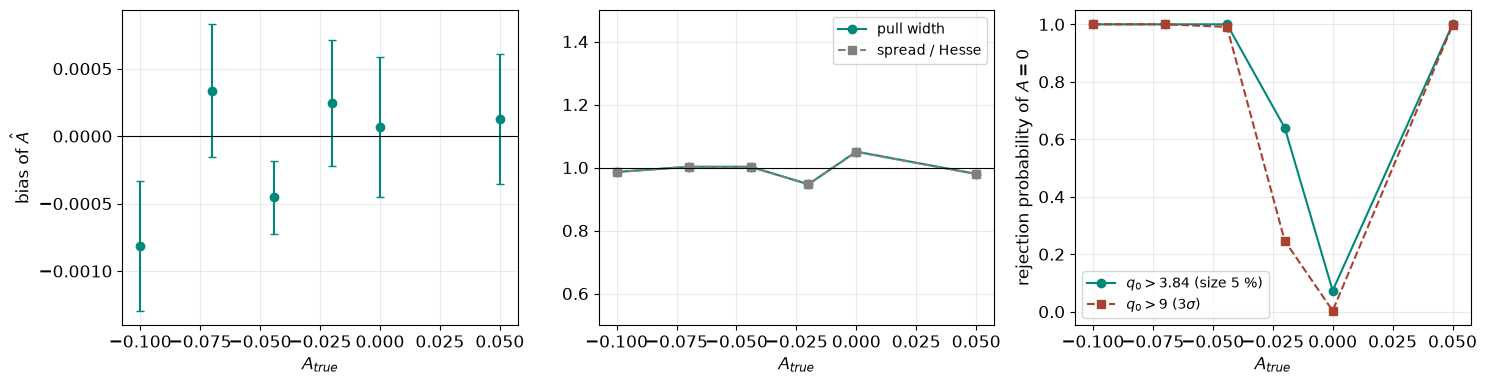

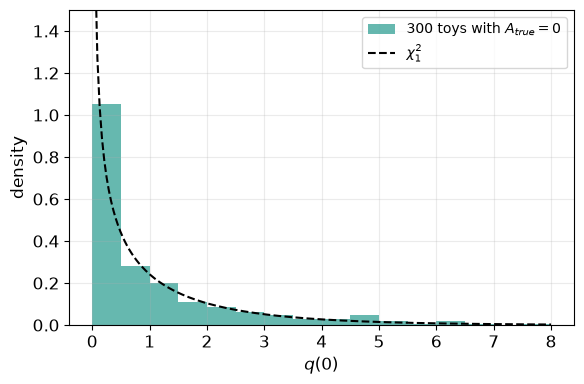

In [14]:
# summary per injected value of A, saved, and the figure of bias, pulls and power
rows_s = []
for a_true, g in toys.groupby("A_true"):
    pull = (g.A - a_true) / g.sigma
    rows_s.append(dict(A_true=a_true, n=len(g), bias=g.A.mean() - a_true, bias_err=g.A.std() / np.sqrt(len(g)),
                       spread_over_hesse=g.A.std() / g.sigma.mean(), pull_mean=pull.mean(), pull_sd=pull.std(),
                       cov68=np.mean(g.t <= 1), cov95=np.mean(g.t <= 3.84),
                       p_q0_gt_3p84=np.mean(g.q0 > 3.84), p_q0_gt_9=np.mean(g.q0 > 9)))
toy_summary = pd.DataFrame(rows_s)
toy_summary.to_csv("results/02_toy_summary.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].errorbar(toy_summary.A_true, toy_summary.bias, toy_summary.bias_err, fmt="o", color=C["freq"], capsize=3)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set(xlabel="$A_{true}$", ylabel="bias of $\\hat A$")
ax[1].plot(toy_summary.A_true, toy_summary.pull_sd, "o-", color=C["freq"], label="pull width")
ax[1].plot(toy_summary.A_true, toy_summary.spread_over_hesse, "s--", color="gray", label="spread / Hesse")
ax[1].axhline(1, color="k", lw=0.8); ax[1].set(xlabel="$A_{true}$", ylim=(0.5, 1.5)); ax[1].legend()
ax[2].plot(toy_summary.A_true, toy_summary.p_q0_gt_3p84, "o-", color=C["freq"], label="$q_0>3.84$ (size 5 %)")
ax[2].plot(toy_summary.A_true, toy_summary.p_q0_gt_9, "s--", color=C["bayes"], label="$q_0>9$ ($3\\sigma$)")
ax[2].set(xlabel="$A_{true}$", ylabel="rejection probability of $A=0$"); ax[2].legend()
plt.tight_layout(); save_fig("02_bias_pulls_power")

# distribution of q(0) when A = 0 is true: it must follow chi2 with one degree of freedom (Wilks)
q0_null = toys[toys.A_true == 0.0].q0.to_numpy()
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(q0_null, bins=np.linspace(0, 8, 17), density=True, color=C["freq"], alpha=0.6, label=f"{len(q0_null)} toys with $A_{{true}}=0$")
x = np.linspace(0.05, 8, 200); ax.plot(x, chi2.pdf(x, 1), "k--", label="$\\chi^2_1$")
ax.set(xlabel="$q(0)$", ylabel="density", ylim=(0, 1.5)); ax.legend()
plt.tight_layout(); save_fig("02_null_distribution_q0")

The size is the line $A_{\rm true}=0$ of the last columns (P($q_0>3.84$) ≈ 0.05), the power the other lines.
With $\sim2\times10^4$ candidates an asymmetry of $-0.02$ is rejected only about two times out of three: below
$\sim0.02$ the test is not sensitive. The $5.2\sigma$ of the data is an *extrapolation* of the $\chi^2_1$ tail, which
the toys only probe down to $\sim3\sigma$.

**Neyman belt.** For each $A_{\rm true}$ of the grid the central 68 % and 95 % ranges of $\hat A$ (percentiles of the
toys); the interval of $A_{\rm true}$ whose belt contains the observed $\hat A$ is the confidence interval.

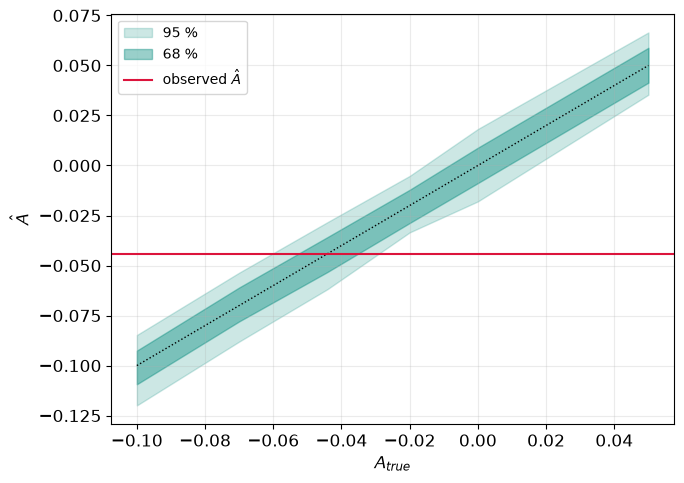

Neyman 68% interval: [-0.0526, -0.0351]   (report: [-0.0528, -0.0351]; Minos [-0.0526, -0.0356])


In [15]:
# confidence belt: for each A_true the central 68 % and 95 % ranges of the estimates (percentiles of the toys)
belt = toys.groupby("A_true").A.quantile([0.025, 0.16, 0.5, 0.84, 0.975]).unstack()
fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(belt.index, belt[0.025], belt[0.975], color=C["freq"], alpha=0.2, label="95 %")
ax.fill_between(belt.index, belt[0.16], belt[0.84], color=C["freq"], alpha=0.4, label="68 %")
ax.plot(belt.index, belt.index, "k:", lw=1)
ax.axhline(A_hat, color=C["model"], label="observed $\\hat A$")
ax.set(xlabel="$A_{true}$", ylabel="$\\hat A$"); ax.legend()
plt.tight_layout(); save_fig("02_neyman_belt")
# Neyman interval: the values of A_true whose 68 % belt contains the observed estimate (linear interpolation)
lo_edge = np.interp(A_hat, belt[0.84].values, belt.index.values)    # A_true where the upper edge crosses A_hat
hi_edge = np.interp(A_hat, belt[0.16].values, belt.index.values)    # A_true where the lower edge crosses A_hat
print(f"Neyman 68% interval: [{lo_edge:+.4f}, {hi_edge:+.4f}]   (report: [-0.0528, -0.0351]; Minos [-0.0526, -0.0356])")

**Dependence on the momentum of the $B$.** If the asymmetry were produced by a detector effect that depends on the
kinematics it would vary with $p_T$ or $p$. We split the sample in terciles and refit each (report, additional results:
$A_{\rm raw}$ stable within uncertainties).

pT  tercile 1 [  1.0,   4.7] GeV  n=6577  A = -0.0563 +- 0.0169


pT  tercile 2 [  4.7,   8.2] GeV  n=6577  A = -0.0363 +- 0.0141


pT  tercile 3 [  8.2,  30.5] GeV  n=6577  A = -0.0452 +- 0.0134


p   tercile 1 [ 26.7,  78.1] GeV  n=6577  A = -0.0390 +- 0.0139


p   tercile 2 [ 78.1, 110.1] GeV  n=6577  A = -0.0475 +- 0.0149


p   tercile 3 [110.1, 288.5] GeV  n=6577  A = -0.0479 +- 0.0153


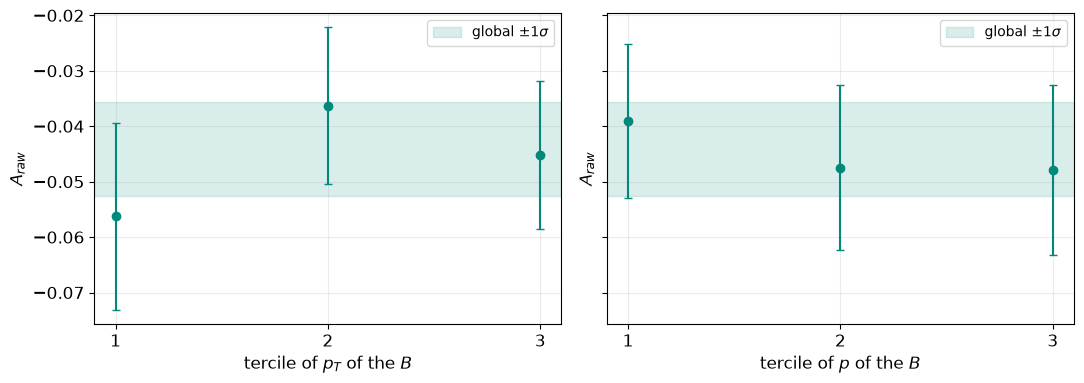

In [16]:
rows_m = []
for var in ("pT", "p"):
    # terciles of the variable: three bins with the same number of candidates
    edges_q = sample[var].quantile([0, 1/3, 2/3, 1]).values
    for k in range(3):
        s = sample[(sample[var] >= edges_q[k]) & (sample[var] <= edges_q[k + 1])]
        f = fit_joint(s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy(), best_vals); f.hesse()   # nominal fit in the bin
        rows_m.append(dict(variable=var, tercile=k + 1, lo_GeV=edges_q[k] / 1e3, hi_GeV=edges_q[k + 1] / 1e3,
                           n=len(s), A=f.values["A"], err=f.errors["A"]))
        print(f"{var:3s} tercile {k + 1} [{edges_q[k]/1e3:5.1f}, {edges_q[k + 1]/1e3:5.1f}] GeV  n={len(s)}  "
              f"A = {f.values['A']:+.4f} +- {f.errors['A']:.4f}")
mom = pd.DataFrame(rows_m)
mom.to_csv("results/02_momentum_terciles.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (var, lab) in zip(ax, (("pT", "$p_T$ of the $B$"), ("p", "$p$ of the $B$"))):
    g = mom[mom.variable == var]
    a.errorbar(g.tercile, g.A, g.err, fmt="o", color=C["freq"], capsize=3)
    a.axhspan(A_hat - fit.errors["A"], A_hat + fit.errors["A"], color=C["freq"], alpha=0.15, label="global $\\pm1\\sigma$")
    a.set(xlabel=f"tercile of {lab}", ylabel="$A_{raw}$", xticks=[1, 2, 3]); a.legend()
plt.tight_layout(); save_fig("02_momentum_terciles")

**Goodness of fit and the binning.** The binned $\chi^2$ of the data is $160$ for $88$ degrees of freedom
($p\sim5\times10^{-6}$): the model is not perfect. Is this $p$-value to be trusted, and does it depend on the binning?
We compute the $\chi^2$ of toy experiments **from the fitted model** (where the model is true by construction) with 10 MeV
and 2.5 MeV bins: their distribution is the reference for the data. *Report:* 1000 toys. Here 30.

 bin width  ndof  data chi2  toys mean  p (chi2 dist.)  sigma-equivalent
    10.0MeV    88      159.5       88.5         4.8e-06               4.6
     2.5MeV   388      441.7      388.2         3.1e-02               2.2


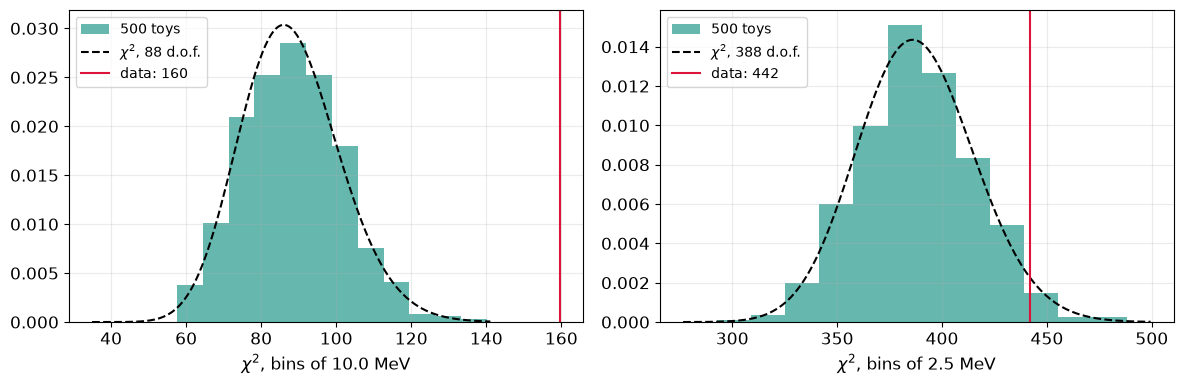

report: p ~ 5e-6 (5.4 sigma) in 10 MeV bins and p = 0.03 (2.0 sigma) in 2.5 MeV bins; the toy chi2 follows its asymptotic
distribution (mean ~ ndof), so the p-values are accurate: the misfit lives on the scale of the flanks of the peak


In [17]:
def chi2_binned_joint(m_p, m_n, v, width):
    """Pearson chi2 of a joint fit with parameters v, bins of the given width, both charges."""
    e = np.arange(LO, HI + 1e-9, width)
    nu_p = expected_counts(model_pos, [v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_pos", "lam1_pos", "lam2_pos", "f_pos")], e)
    nu_n = expected_counts(model_neg, [v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_neg", "lam1_neg", "lam2_neg", "f_neg")], e)
    chi2_ = np.sum((np.histogram(m_p, e)[0] - nu_p)**2 / nu_p) + np.sum((np.histogram(m_n, e)[0] - nu_n)**2 / nu_n)
    return chi2_, 2 * (len(e) - 1) - 12                       # chi2 and degrees of freedom

gof = {10.0: [], 2.5: []}                                     # chi2 of the toys for the two bin widths
for k in range(500):
    mp_t, mn_t = make_toy(best_vals, A_hat)                   # toy from the fitted model: the model is true by construction
    f_t = fit_joint(mp_t, mn_t, best_vals)                    # refit it
    for width in gof:
        gof[width].append(chi2_binned_joint(mp_t, mn_t, f_t.values, width)[0])
print(f"{'bin width':>10s} {'ndof':>5s} {'data chi2':>10s} {'toys mean':>10s} {'p (chi2 dist.)':>15s} {'sigma-equivalent':>17s}")
for width, vals in gof.items():
    c2_data, nd = chi2_binned_joint(m_pos, m_neg, fit.values, width)        # chi2 of the real data
    p_ = chi2.sf(c2_data, nd)
    print(f"{width:8.1f}MeV {nd:5d} {c2_data:10.1f} {np.mean(vals):10.1f} {p_:15.1e} {norm.isf(p_ / 2):17.1f}")
# distribution of the chi2 of the toys against its asymptotic law, with the value of the data
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (width, vals) in zip(ax, gof.items()):
    c2_data, nd = chi2_binned_joint(m_pos, m_neg, fit.values, width)
    a.hist(vals, bins=12, density=True, color=C["freq"], alpha=0.6, label=f"{len(vals)} toys")
    x = np.linspace(nd - 4 * np.sqrt(2 * nd), nd + 4 * np.sqrt(2 * nd), 300)
    a.plot(x, chi2.pdf(x, nd), "k--", label=f"$\\chi^2$, {nd} d.o.f.")
    a.axvline(c2_data, color=C["model"], label=f"data: {c2_data:.0f}")
    a.set(xlabel=f"$\\chi^2$, bins of {width} MeV"); a.legend()
plt.tight_layout(); save_fig("02_gof_binning")
pd.DataFrame({f"chi2_{w}MeV": v for w, v in gof.items()}).to_csv("results/02_gof_toys.csv", index=False)
print("report: p ~ 5e-6 (5.4 sigma) in 10 MeV bins and p = 0.03 (2.0 sigma) in 2.5 MeV bins; the toy chi2 follows its asymptotic")
print("distribution (mean ~ ndof), so the p-values are accurate: the misfit lives on the scale of the flanks of the peak")

## Results saved

In [18]:
summary = dict(
    bootstrap_coverage68=dict(value=float(cov68), error=float(err68), n_replicas=int(len(boot))),
    toys=dict(n=int(len(toys)), neyman_interval68=[float(lo_edge), float(hi_edge)]),
    goodness_of_fit_toys={str(w): float(np.mean(v)) for w, v in gof.items()})
json.dump(summary, open("results/02_summary.json", "w"), indent=1)
boot.to_csv("results/02_bootstrap.csv", index=False); toys.to_csv("results/02_toys.csv", index=False)
print("saved results/02_summary.json and the tables; figures in figures/")

saved results/02_summary.json and the tables; figures in figures/


## Summary
* The bootstrap and the toys give **coverage compatible with nominal**, pulls of width $\approx1$ and no bias: the
  estimator is unbiased and reaches the minimum variance bound.
* The test of $A=0$ has the **nominal size** (5 %); its power is $\approx1$ at the fitted value and low below
  $|A|\sim0.02$ with this sample.
* The Neyman construction gives the same interval as the likelihood ratio.
* $A_{\rm raw}$ does not depend on the momentum of the $B$; the $p$-value of the binned $\chi^2$ depends on the binning.

In [19]:
print(f"Running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Running time of this notebook: 105.8 min
